<a href="https://colab.research.google.com/github/garrettdsparks/SDP-CSE21-ME24/blob/elliston-dev/boiler_identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics roboflow

import torch
import os
import glob
from ultralytics import YOLO
from google.colab import drive, userdata
from roboflow import Roboflow
from PIL import Image

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch Version: 2.11.0+cu130
CUDA Available: True
Device Name: Tesla T4


Mount Google Drive for data storage

In [ ]:
drive.mount('/content/drive')

subfolder_name = "boiler_identification"

save_dir = os.path.join("/content/drive/MyDrive/SDP_Team_21", subfolder_name)
os.makedirs(save_dir, exist_ok=True)
print(f"Output directory ready: {save_dir}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output directory ready: /content/drive/MyDrive/SDP_Team_21/boiler_identification


Access Roboflow

In [ ]:
rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY')) # stored in Colab Secrets
project = rf.workspace("ellistons-workspace").project("boiler_identification")
version = project.version(4)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to boiler_identification-4 in yolov8:: 100%|██████████| 339/339 [00:00<00:00, 4252.64it/s]


Train model

In [ ]:
from ultralytics import YOLO
import os

model = YOLO("yolov8n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=60,
    patience=15,
    imgsz=512,
    batch=8,
    device=0,
    project=save_dir,
    name="boiler_tuned_hparams",
    exist_ok=True,

    optimizer="auto",
    lr0=0.01,
    box=7.5,
    cls=0.5,
    mosaic=1.0,
    scale=0.5
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/boiler_identification-4/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=boiler_tuned_hparams, nbs=64, nms=None, opset=No


image 1/1 /content/boiler_identification-4/valid/images/fuel3_webp.rf.f8d34a2d44485a73f87c576ceac4fc45.jpg: 512x512 (no detections), 20.1ms
Speed: 1.9ms preprocess, 20.1ms inference, 2.9ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/drive/MyDrive/SDP_Team_21/boiler_identification/inference_output


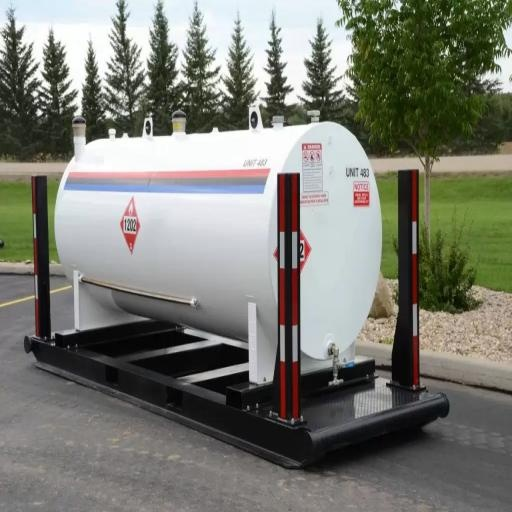


image 1/1 /content/boiler_identification-4/valid/images/control_webp.rf.d931912ae6351f8b07d37bcf82173fbb.jpg: 512x512 (no detections), 41.2ms
Speed: 1.0ms preprocess, 41.2ms inference, 3.7ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/drive/MyDrive/SDP_Team_21/boiler_identification/inference_output


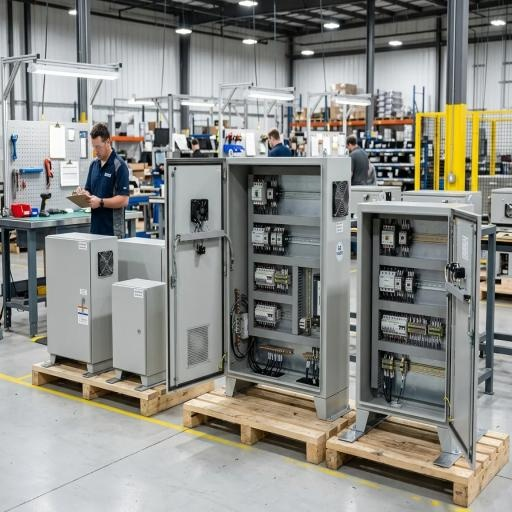


image 1/1 /content/boiler_identification-4/valid/images/Screenshot-2026-10-19-at-4-07-33-PM_png.rf.90c58abfd06cba390c2e42cd247f8ab0.jpg: 512x512 1 Boiler, 21.4ms
Speed: 3.0ms preprocess, 21.4ms inference, 4.0ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/drive/MyDrive/SDP_Team_21/boiler_identification/inference_output


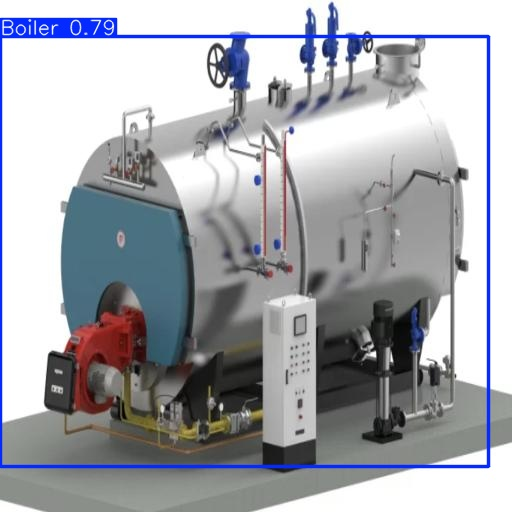


image 1/1 /content/boiler_identification-4/valid/images/empty_webp.rf.a2619dd665f833710e00821269b7dd4f.jpg: 512x512 (no detections), 16.9ms
Speed: 0.9ms preprocess, 16.9ms inference, 2.2ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/drive/MyDrive/SDP_Team_21/boiler_identification/inference_output


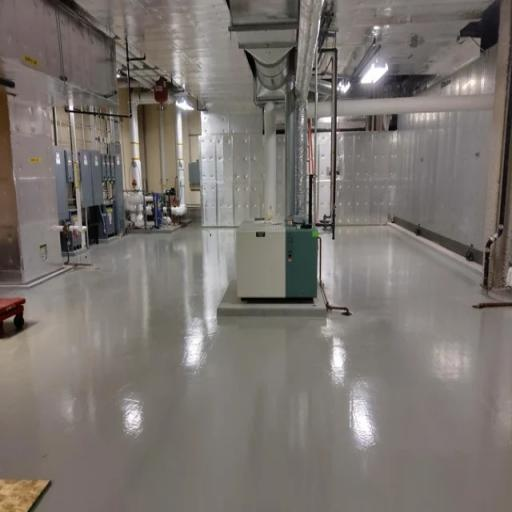


image 1/1 /content/boiler_identification-4/valid/images/Gemini_Generated_Image_ruxbmpruxbmpruxb_jpeg.rf.1dad8e5a5c415bedd91b028ca0135480.jpg: 512x512 1 Boiler, 21.4ms
Speed: 1.0ms preprocess, 21.4ms inference, 2.3ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/drive/MyDrive/SDP_Team_21/boiler_identification/inference_output


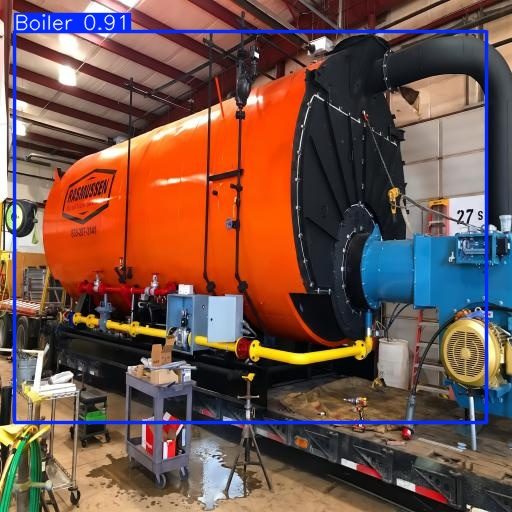


image 1/1 /content/boiler_identification-4/valid/images/images_jpeg.rf.31bf377ec176d6b7a64c9f009297a047.jpg: 512x512 1 Boiler, 28.3ms
Speed: 4.9ms preprocess, 28.3ms inference, 5.8ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/drive/MyDrive/SDP_Team_21/boiler_identification/inference_output


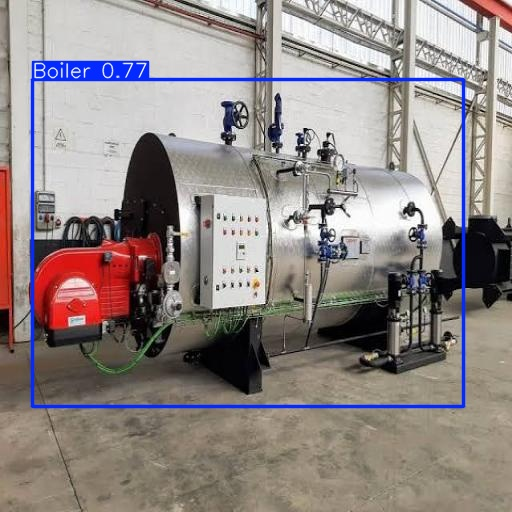


image 1/1 /content/boiler_identification-4/valid/images/ahu_jpg.rf.9d6a09f3c22099ad36a269aa06a9419f.jpg: 512x512 (no detections), 25.9ms
Speed: 8.1ms preprocess, 25.9ms inference, 1.2ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/drive/MyDrive/SDP_Team_21/boiler_identification/inference_output


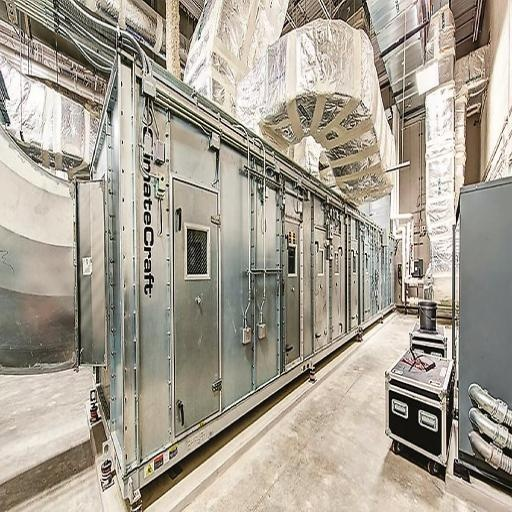


image 1/1 /content/boiler_identification-4/valid/images/boiler3_webp.rf.7c7f35a9d193670cd3b41bd3480d9b49.jpg: 512x512 1 Boiler, 21.8ms
Speed: 4.4ms preprocess, 21.8ms inference, 5.1ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/drive/MyDrive/SDP_Team_21/boiler_identification/inference_output


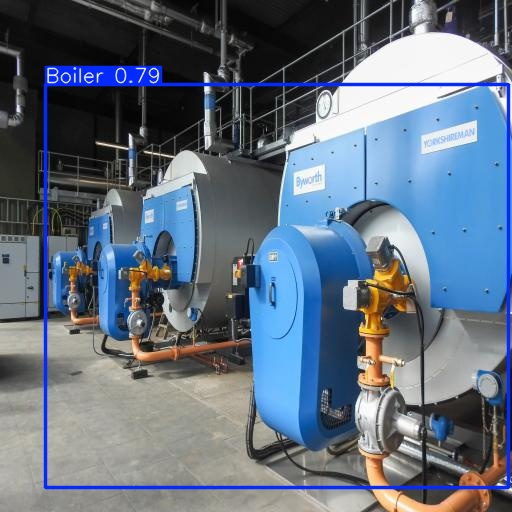

In [ ]:
best_weights = os.path.join(save_dir, "boiler_tuned_hparams", "weights", "best.pt")
trained_model = YOLO(best_weights)

candidate_images = glob.glob(f"{dataset.location}/valid/images/*.*")

if candidate_images:
    for img in range(0, len(candidate_images)):
        img_path = candidate_images[img]

        pred_results = trained_model.predict(
            source=img_path,
            conf=0.60,
            save=True,
            project=save_dir,
            name="inference_output",
            exist_ok=True
        )

        output_path = os.path.join(pred_results[0].save_dir, os.path.basename(img_path))
        if os.path.exists(output_path):
            display(Image.open(output_path))